# Volar con criterio: análisis comparativo de Wingo, LATAM y Avianca en rutas nacionales de Colombia (Opción B)
**Integrantes:** Manuela Pardo, Valerie Ramírez, Sebastián Plata y Luisa Espinosa  

##**Instrucciones de ejecución**
1. Cargar los siguientes archivos en el directorio de Google Colab (ícono de carpeta a la izquierda) antes de ejecutar las celdas (`Entorno de ejecución > Ejecutar todas`):
- `base_aerea.csv`: Base pública de Tráfico Origen-Destino de la Aerocivil (Datos Abiertos Colombia).
- `tarifas_rutas.csv`: Tabla elaborada por el grupo con tarifas base, duración y escalas.
- `tarifas_equipaje.csv`: Tabla elaborada por el grupo con costos adicionales de equipaje y asiento.

**Bases de datos para ser descargadas:**
https://drive.google.com/drive/folders/1N3Q8nIN5htAiLiDm3wy7yjKfHjeRBs2c?usp=sharing

**Informe del proyecto:**
https://docs.google.com/document/d/1-OPg_I4wCYoJwbNRFubptlsaw2JdirOmO0uCSdLsBzk/edit?usp=sharing


## 1. Carga y exploración inicial de la base de datos (Aerocivil)
Cargamos la base de datos pública *Transporte Aéreo Comercial - Tráfico Origen-Destino* (`base_aerea.csv`), obtenida a través de la página de datos del gobierno. Al inspeccionar la estructura original con `info()' y `head()`, identificamos que las columnas y valores contienen comillas dobles adicionales y las variables numéricas (`Año` y `Pasajeros`) están almacenadas como texto con comas de miles.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#Cargar la base a[erea de datos, evitando que tome la primera columna como índice
df = pd.read_csv('base_aerea.csv', index_col=False)

#Exploración inicial de columnas y tipos de datos
print("Dimensiones originales de la base:", df.shape)
display(df.head(3))
df.info()

Dimensiones originales de la base: (478010, 16)


,Sigla Empresa,Nombre,Año,Número de Mes,Origen,Nombre Origen,Ciudad Origen,Pais Origen,Destino,Nombre Destino,Ciudad Destino,Pais Destino,Tráfico (N/I),Tipo Vuelo,Pasajeros,Carga_Correo (Kg)
0,0EC,SAE,"2,020",1,7IY,HATO SAN JOSE,LA PRIMAVERA,COLOMBIA,VVC,VANGUARDIA,VILLAVICENCIO,COLOMBIA,N,T,5,0
1,0EC,SAE,"2,020",1,7KA,SAN CAMILO,CUMARIBO,COLOMBIA,VVC,VANGUARDIA,VILLAVICENCIO,COLOMBIA,N,T,2,18
2,0EC,SAE,"2,020",1,9DI,SAN FELIPE,SAN FELIPE,COLOMBIA,IDA,CESAR GAVIRIA TRUJILLO,PUERTO INIRIDA,COLOMBIA,N,T,9,45


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478010 entries, 0 to 478009
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   Sigla Empresa      478010 non-null  object
 1   Nombre             478010 non-null  object
 2   Año                478010 non-null  object
 3   Número de Mes      478010 non-null  int64 
 4   Origen             478010 non-null  object
 5   Nombre Origen      478010 non-null  object
 6   Ciudad Origen      478010 non-null  object
 7   Pais Origen        478010 non-null  object
 8   Destino            478010 non-null  object
 9   Nombre Destino     478010 non-null  object
 10  Ciudad Destino     478010 non-null  object
 11  Pais Destino       478010 non-null  object
 12  Tráfico (N/I)      478010 non-null  object
 13  Tipo Vuelo         478010 non-null  object
 14  Pasajeros          477958 non-null  object
 15  Carga_Correo (Kg)  478010 non-null  object
dtypes: int64(1), object(

## 2. Limpieza, filtrado y estandarización de aerolíneas
Para dejar la base lista para el análisis, aplicamos los siguientes pasos de limpieza y filtros:
* **Limpieza de caracteres:** Eliminamos las comillas dobles de los encabezados y registros.
* **Filtro de tráfico:** Conservamos únicamente los vuelos nacionales (`Tráfico (N/I) == 'N'`).
* **Estandarización de empresas:** Agrupamos las razones sociales registradas ante la Aerocivil bajo sus marcas comerciales actuales: `AVIANCA` y `AVIANCA EXPRESS` como **Avianca**; `AIRES` y `LATAM AIRLINES GROUP S.A SUCURSAL COLOMBIA` como **LATAM**; y `AEROREPUBLICA` como **Wingo**.
* **Conversión numérica:** Eliminamos comas de miles y transformamos `Año`, `Número de Mes` y `Pasajeros` a formato numérico.

In [ ]:
#Este código quita las comillas dobles y espacios extra en columnas y valores
df.columns = df.columns.str.replace('"', '').str.strip()
for col in df.columns:
    df[col] = df[col].astype(str).str.replace('"', '').str.strip()

#Este código filtra los vuelos nacionales únicamente (N), y elimina los vuelos innacionales ('I')
df_nacional = df[df['Tráfico (N/I)'] == 'N'].copy()

#Este código standariza los nombres comerciales de las tres aerolíneas
mapa_aerolineas = {
    'AVIANCA': 'Avianca',
    'AVIANCA EXPRESS': 'Avianca',
    'AIRES': 'LATAM',
    'LATAM AIRLINES GROUP S.A SUCURSAL COLOMBIA': 'LATAM',
    'AEROREPUBLICA': 'Wingo'
}

df_filtrado = df_nacional[df_nacional['Nombre'].isin(mapa_aerolineas.keys())].copy()
df_filtrado['Aerolinea'] = df_filtrado['Nombre'].map(mapa_aerolineas)

#Este código convierte las variables ubicadas en clave a tipo numérico
df_filtrado['Año'] = pd.to_numeric(df_filtrado['Año'].str.replace(',', ''), errors='coerce')
df_filtrado['Número de Mes'] = pd.to_numeric(df_filtrado['Número de Mes'], errors='coerce')
df_filtrado['Pasajeros'] = pd.to_numeric(df_filtrado['Pasajeros'].str.replace(',', ''), errors='coerce').fillna(0)

#Este código crea la columna de Ruta limpia
df_filtrado['Ruta'] = df_filtrado['Ciudad Origen'] + ' - ' + df_filtrado['Ciudad Destino']

print("Registros nacionales limpios de Avianca, LATAM y Wingo:", len(df_filtrado))
display(df_filtrado[['Aerolinea', 'Año', 'Número de Mes', 'Ruta', 'Pasajeros']].head())

print(df_filtrado['Aerolinea'].value_counts())

Registros nacionales limpios de Avianca, LATAM y Wingo: 36330


,Aerolinea,Año,Número de Mes,Ruta,Pasajeros
20322,LATAM,2020,1,SAN ANDRES - ISLA - BARRANQUILLA,310
20323,LATAM,2020,1,SAN ANDRES - ISLA - BUCARAMANGA,689
20324,LATAM,2020,1,SAN ANDRES - ISLA - BOGOTA,13541
20325,LATAM,2020,1,SAN ANDRES - ISLA - CALI,1691
20326,LATAM,2020,1,SAN ANDRES - ISLA - CALI,11993


Aerolinea
Avianca    29450
LATAM       5217
Wingo       1663
Name: count, dtype: int64


## 3. Análisis de participación de mercado, cobertura y evolución histórica
Agrupamos los registros por aerolínea para comparar el total de pasajeros movilizados, la participación de mercado y la cobertura geográfica (rutas y destinos únicos). Posteriormente, graficamos la evolución anual de pasajeros entre 2020 y 2026. La caída observada en 2026 responde a que la base oficial solo incluye registros parciales de los primeros meses de dicho año.

,Aerolinea,Total_Pasajeros,Rutas_Unicas,Destinos_Unicos,Participacion_%
0,Avianca,73331524,852,37,55.70
1,LATAM,49157921,248,26,37.34
2,Wingo,9157331,77,15,6.96


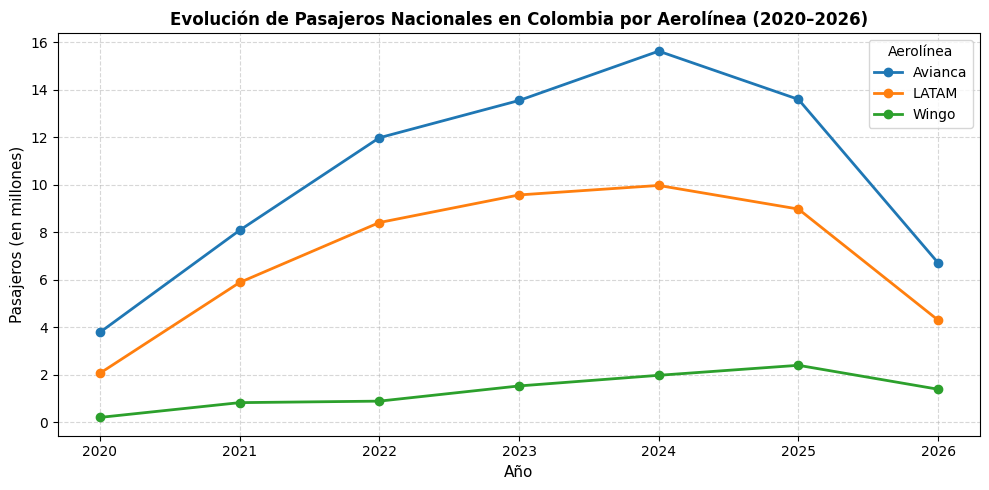

In [ ]:
#Este código organiza las aerolínea de acuerdo a su participación y cobertura
resumen_aerolineas = df_filtrado.groupby('Aerolinea').agg(
    Total_Pasajeros=('Pasajeros', 'sum'),
    Rutas_Unicas=('Ruta', 'unique'),
    Destinos_Unicos=('Ciudad Destino', 'unique')
).reset_index()

resumen_aerolineas['Participacion_%'] = (
    resumen_aerolineas['Total_Pasajeros'] / resumen_aerolineas['Total_Pasajeros'].sum() * 100
).round(2)

display(resumen_aerolineas)

#Este códico crea el gráfico de líneas: Evolución anual de pasajeros nacionales
pasajeros_anio = df_filtrado.groupby(['Año', 'Aerolinea'])['Pasajeros'].sum().unstack()

plt.figure(figsize=(10, 5))
for aerolinea in ['Avianca', 'LATAM', 'Wingo']:
    plt.plot(pasajeros_anio.index, pasajeros_anio[aerolinea] / 1e6, marker='o', linewidth=2, label=aerolinea)

plt.title('Evolución de Pasajeros Nacionales en Colombia por Aerolínea (2020–2026)', fontsize=12, fontweight='bold')
plt.xlabel('Año', fontsize=11)
plt.ylabel('Pasajeros (en millones)', fontsize=11)
plt.xticks(pasajeros_anio.index)
plt.legend(title='Aerolínea')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Análisis de Base 2: Tarifas base y tiempos de vuelo por ruta
Cargamos la tabla `tarifas_rutas.csv`, que recoge los precios mínimos publicados (solo artículo personal), la duración y las escalas en las cinco rutas nacionales principales desde Bogotá. Agrupamos por aerolínea para obtener su tarifa base promedio y visualizar las diferencias de precio por destino.

,Aerolinea,Rutas_Disponibles,Tarifa_Base_Prom_COP,Tarifa_Min_COP,Tarifa_Max_COP,Duracion_Prom_Min
0,Avianca,5,529040.0,308110.0,729700.0,88.0
1,LATAM,5,334780.0,227190.0,474900.0,90.0
2,Wingo,4,371484.0,208520.0,602317.0,80.0


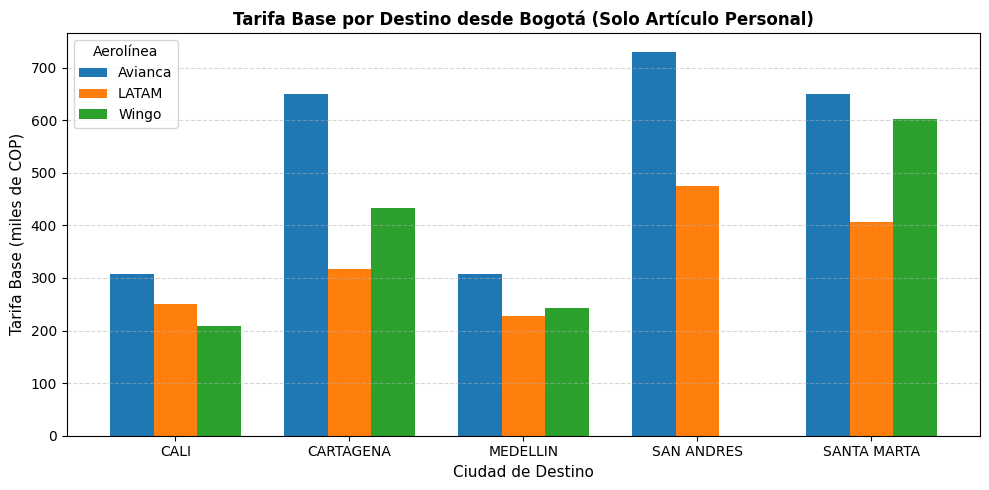

In [ ]:
import numpy as np

# Este código carga y limpia espacios en la Base 2
rutas = pd.read_csv('tarifas_rutas.csv', sep=';')
rutas['Destino'] = rutas['Destino'].str.strip()

#Este código resume las tarifas base por cada aerolínea
resumen_rutas = rutas.groupby('Aerolinea').agg(
    Rutas_Disponibles=('Tarifa_Base_COP', 'count'),
    Tarifa_Base_Prom_COP=('Tarifa_Base_COP', 'mean'),
    Tarifa_Min_COP=('Tarifa_Base_COP', 'min'),
    Tarifa_Max_COP=('Tarifa_Base_COP', 'max'),
    Duracion_Prom_Min=('Duracion_min', 'mean')
).round(0).reset_index()

display(resumen_rutas)

#Este código crea el Gráfico de Base 2: Tarifa base por ruta y aerolínea
pivot_rutas = rutas.pivot(index='Destino', columns='Aerolinea', values='Tarifa_Base_COP') / 1000
pivot_rutas = pivot_rutas[['Avianca', 'LATAM', 'Wingo']]

ax = pivot_rutas.plot(kind='bar', figsize=(10, 5), width=0.75, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title('Tarifa Base por Destino desde Bogotá (Solo Artículo Personal)', fontsize=12, fontweight='bold')
plt.xlabel('Ciudad de Destino', fontsize=11)
plt.ylabel('Tarifa Base (miles de COP)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(title='Aerolínea')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Análisis de Base 3: Estructura de cobros por equipaje adicional
Cargamos `tarifas_equipaje.csv` para comparar los recargos estándar por maleta de cabina y primera maleta en bodega en vuelos nacionales, identificando qué aerolínea penaliza más al pasajero que viaja con equipaje.

,Aerolinea,Articulo_Personal_COP,Maleta_Cabina_COP,Peso_Cabina_kg,Maleta_Bodega_1_COP,Peso_Bodega_kg
0,Avianca,0,79900,10,79900,23
1,LATAM,0,74039,12,74489,23
2,Wingo,0,48990,12,35000,23


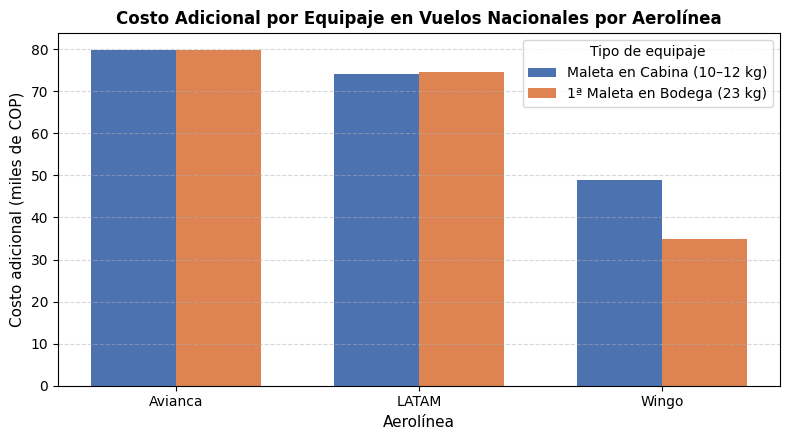

In [ ]:
#Este código carga la Base 3
equipaje = pd.read_csv('tarifas_equipaje.csv')
display(equipaje[['Aerolinea', 'Articulo_Personal_COP', 'Maleta_Cabina_COP', 'Peso_Cabina_kg', 'Maleta_Bodega_1_COP', 'Peso_Bodega_kg']])

#Este código crea el Gráfico de Base 3: Comparación de costos adicionales de equipaje
x = np.arange(len(equipaje['Aerolinea']))
ancho = 0.35

plt.figure(figsize=(8, 4.5))
plt.bar(x - ancho/2, equipaje['Maleta_Cabina_COP'] / 1000, width=ancho, label='Maleta en Cabina (10–12 kg)', color='#4C72B0')
plt.bar(x + ancho/2, equipaje['Maleta_Bodega_1_COP'] / 1000, width=ancho, label='1ª Maleta en Bodega (23 kg)', color='#DD8452')

plt.title('Costo Adicional por Equipaje en Vuelos Nacionales por Aerolínea', fontsize=12, fontweight='bold')
plt.xlabel('Aerolínea', fontsize=11)
plt.ylabel('Costo adicional (miles de COP)', fontsize=11)
plt.xticks(x, equipaje['Aerolinea'])
plt.legend(title='Tipo de equipaje')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Integración de las 3 bases: Cobertura, Tarifas y Costo Real con Equipaje
Finalmente, unimos (`pd.merge`) los resultados de las tres fuentes usando `Aerolinea` como llave común: la participación y cobertura histórica (Base 1), el promedio de tarifas por ruta (Base 2) y los recargos de equipaje (Base 3). Esto permite calcular el costo total promedio de viajar según el perfil del pasajero.

,Aerolinea,Participacion_%,Destinos_Unicos,Rutas_Disponibles,Tarifa_Base_Prom_COP,Total_Con_Cabina_COP,Total_Con_Bodega_COP
0,Avianca,55.70,37,5,529040.0,608940.0,608940.0
1,LATAM,37.34,26,5,334780.0,408819.0,409269.0
2,Wingo,6.96,15,4,371484.0,420474.0,406484.0


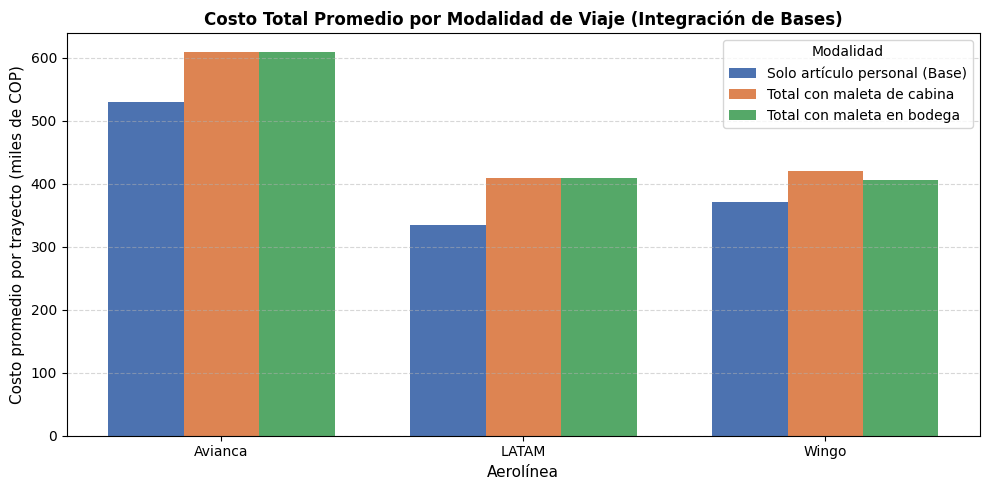

In [ ]:
#Este código une las tres bases
tabla_1_2 = pd.merge(resumen_aerolineas, resumen_rutas, on='Aerolinea')
tabla_final = pd.merge(tabla_1_2, equipaje[['Aerolinea', 'Maleta_Cabina_COP', 'Maleta_Bodega_1_COP']], on='Aerolinea')

#Este código calcula los costos totales promedio (Base + Equipaje)
tabla_final['Total_Con_Cabina_COP'] = (tabla_final['Tarifa_Base_Prom_COP'] + tabla_final['Maleta_Cabina_COP']).round(0)
tabla_final['Total_Con_Bodega_COP'] = (tabla_final['Tarifa_Base_Prom_COP'] + tabla_final['Maleta_Bodega_1_COP']).round(0)

display(tabla_final[['Aerolinea', 'Participacion_%', 'Destinos_Unicos', 'Rutas_Disponibles',
                     'Tarifa_Base_Prom_COP', 'Total_Con_Cabina_COP', 'Total_Con_Bodega_COP']])

#Este código crea el Gráfico final integrado: Impacto del equipaje en el precio promedio total
x = np.arange(len(tabla_final['Aerolinea']))
ancho = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - ancho, tabla_final['Tarifa_Base_Prom_COP'] / 1000, width=ancho, label='Solo artículo personal (Base)', color='#4C72B0')
plt.bar(x, tabla_final['Total_Con_Cabina_COP'] / 1000, width=ancho, label='Total con maleta de cabina', color='#DD8452')
plt.bar(x + ancho, tabla_final['Total_Con_Bodega_COP'] / 1000, width=ancho, label='Total con maleta en bodega', color='#55A868')

plt.title('Costo Total Promedio por Modalidad de Viaje (Integración de Bases)', fontsize=12, fontweight='bold')
plt.xlabel('Aerolínea', fontsize=11)
plt.ylabel('Costo promedio por trayecto (miles de COP)', fontsize=11)
plt.xticks(x, tabla_final['Aerolinea'])
plt.legend(title='Modalidad')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Conclusiones, Limitaciones y Uso de Inteligencia Artificial

### Conclusiones principales
* **Dominio y cobertura geográfica (Base 1 - Aerocivil):** Avianca lidera el mercado aéreo nacional colombiano con el 55.7% de participación y presencia en 37 destinos únicos, seguida por LATAM con el 37.3% y 26 destinos. Wingo mantiene un nicho específico del 7.0% (15 destinos), lo que se reflejó también en nuestra consulta de rutas al no presentar disponibilidad de vuelo para San Andrés en la fecha evaluada.
* **Comportamiento de tarifas base (Base 2 - Rutas):** Contrario a la hipótesis inicial de que una aerolínea low-cost ofrece siempre el tiquete base más económico, **LATAM** registró el menor promedio base en las rutas evaluadas desde Bogotá (COP 334,780 COP), superando a **Wingo** (COP 371,484 COP en las 4 rutas disponibles) y ubicándose muy por debajo de **Avianca** (COP 529,040 COP). Wingo únicamente ofreció la tarifa base más baja en la ruta Bogotá a Cali (COP 208,520 COP).
* **Impacto real del equipaje (Base 3 e Integración):** Aunque Wingo no fue la más barata en tarifa base promedio, su política de equipaje es considerablemente más económica: cobrar una maleta de bodega cuesta $35,000 COP en Wingo, frente a COP 74,489 COP en LATAM y COP 79,900 COP en Avianca. Al integrar los costos totales, viajar con maleta documentada en Wingo (COP 406,484 COP) iguala prácticamente el costo de LATAM (COP 409,269 COP).
* **Recomendación al pasajero:**
  * **Viajero ligero o que busca mayor disponibilidad:** **LATAM** ofrece la mejor relación entre precio base económico, frecuencias diarias y vuelos directos en rutas troncales.
  * **Viajero con maleta en bodega en rutas cubiertas por *low-cost*:** **Wingo** es altamente competitiva gracias a sus bajos recargos por equipaje documentado.
  * **Viajero hacia destinos regionales o intermedios:** **Avianca** es la alternativa indispensable por su amplia red nacional, aunque a un costo significativamente superior.

### Limitaciones del análisis
1. **Tarifas dinámicas (corte transversal):** Los precios recolectados corresponden a una consulta puntual en una fecha específica de temporada alta (diciembre), por lo que pueden variar según la anticipación de compra y la demanda diaria.
2. **Registros parciales de 2026:** La base histórica de la Aerocivil incluye datos completos hasta 2025 y registros parciales de los primeros meses de 2026.
3. **Ausencia de indicadores operativos:** La base pública de tráfico Origen–Destino no reporta puntualidad, demoras ni cancelaciones por aerolínea.

---

### Nota sobre el Uso de Inteligencia Artificial
Para el desarrollo de este proyecto se utilizó **Gemini** como herramienta de apoyo técnico para depurar errores de lectura y delimitadores (`;` y `,`) en archivos CSV, estructurar las operaciones de limpieza, agrupación (`groupby`) y cruce de tablas (`merge`) en `pandas`, y optimizar el formato visual de los gráficos en `Matplotlib`. Todos los filtros de razones sociales de la Aerocivil, los datos consultados en web y las interpretaciones finales fueron verificados manualmente por las integrantes del equipo.

Aca abajo Embelleceremos las graficas.

In [ ]:
#El texto utilizado para embellecer

#Actúa como un graficador. Necesito que en el punto de mas abajo pongas las graficas que generamos anteriormente arriba todas,
#pero mejorandolas lo vamos a llamar embellecer, quiero que uses un font empresarial, que te enfoques con
#diferentes colores para avianca quiero que uses rojo, para latam azul y para wingo morado.
#De resto quiero que dejes la informacion igual.Ten en cuenta que es para un proyecto de investigacion
#elegante asi que hazlo bien.
# no cambies lo titulos que pusimos que asi estan bien si algo la letra para hacerlos mas visibles
#Intenta mejorar el estilo y si vez algo de informacion lo mueves si no nada.

### Versión Embellecida de Gráficos (Estilo Empresarial / Corporativo)

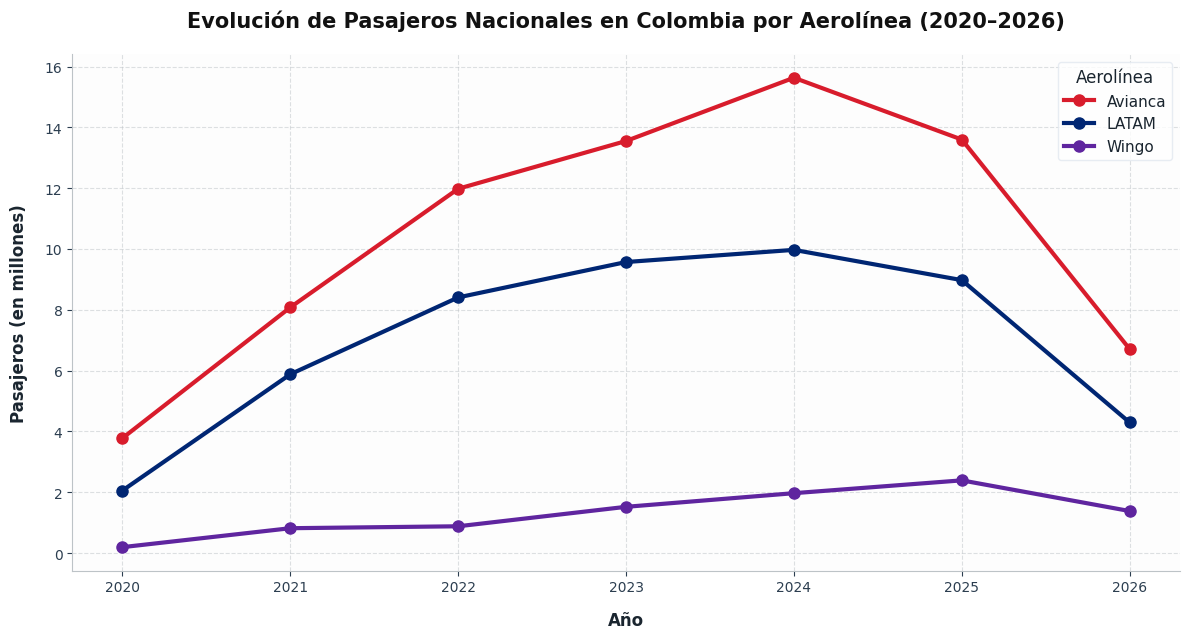

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# --- CONFIGURACIÓN DE ESTILO CORPORATIVO GLOBAL ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['text.color'] = '#1a252f'
plt.rcParams['axes.labelcolor'] = '#1a252f'
plt.rcParams['xtick.color'] = '#2c3e50'
plt.rcParams['ytick.color'] = '#2c3e50'

# Paleta de colores oficial solicitada
colores_aerolineas = {
    'Avianca': '#D81C2C',  # Rojo
    'LATAM': '#002673',    # Azul
    'Wingo': '#5F259F'     # Morado
}

# ----------------------------------------------------------------------------------------
# GRÁFICO 1: Evolución anual de pasajeros nacionales (2020–2026)
# ----------------------------------------------------------------------------------------
pasajeros_anio = df_filtrado.groupby(['Año', 'Aerolinea'])['Pasajeros'].sum().unstack()

fig1, ax1 = plt.subplots(figsize=(12, 6.5), dpi=100)
ax1.set_facecolor('#fdfdfd')

for aerolinea in ['Avianca', 'LATAM', 'Wingo']:
    if aerolinea in pasajeros_anio.columns:
        ax1.plot(
            pasajeros_anio.index,
            pasajeros_anio[aerolinea] / 1e6,
            marker='o',
            markersize=8,
            linewidth=3.0,
            color=colores_aerolineas[aerolinea],
            label=aerolinea
        )

# Título original exacto, más visible y elegante
ax1.set_title('Evolución de Pasajeros Nacionales en Colombia por Aerolínea (2020–2026)', fontsize=15, fontweight='bold', pad=20, color='#111111')
ax1.set_xlabel('Año', fontsize=12, fontweight='semibold', labelpad=12)
ax1.set_ylabel('Pasajeros (en millones)', fontsize=12, fontweight='semibold', labelpad=12)
ax1.set_xticks(pasajeros_anio.index)
ax1.grid(True, linestyle='--', alpha=0.5, color='#bdc3c7')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#bdc3c7')
ax1.spines['bottom'].set_color('#bdc3c7')

ax1.legend(title='Aerolínea', fontsize=11, title_fontsize=12, frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0', shadow=False)
plt.tight_layout()
plt.show()

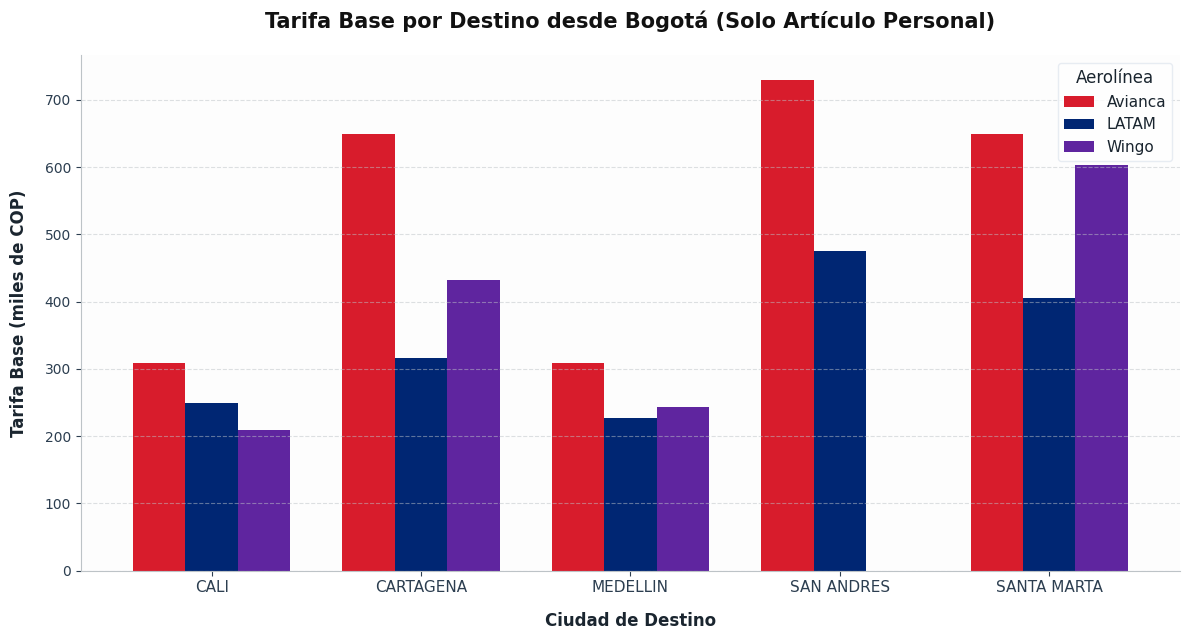

In [ ]:
# ----------------------------------------------------------------------------------------
# GRÁFICO 2: Tarifa Base por Destino desde Bogotá (Solo Artículo Personal)
# ----------------------------------------------------------------------------------------
import matplotlib.pyplot as plt

# --- CONFIGURACIÓN DE ESTILO CORPORATIVO GLOBAL ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['text.color'] = '#1a252f'
plt.rcParams['axes.labelcolor'] = '#1a252f'
plt.rcParams['xtick.color'] = '#2c3e50'
plt.rcParams['ytick.color'] = '#2c3e50'

colores_aerolineas = {
    'Avianca': '#D81C2C',  # Rojo
    'LATAM': '#002673',    # Azul
    'Wingo': '#5F259F'     # Morado
}

pivot_rutas_plot = pivot_rutas[['Avianca', 'LATAM', 'Wingo']]

fig2, ax2 = plt.subplots(figsize=(12, 6.5), dpi=100)
ax2.set_facecolor('#fdfdfd')

colors_list = [colores_aerolineas['Avianca'], colores_aerolineas['LATAM'], colores_aerolineas['Wingo']]
pivot_rutas_plot.plot(kind='bar', ax=ax2, width=0.75, color=colors_list)

# Título original exacto, más visible y elegante
ax2.set_title('Tarifa Base por Destino desde Bogotá (Solo Artículo Personal)', fontsize=15, fontweight='bold', pad=20, color='#111111')
ax2.set_xlabel('Ciudad de Destino', fontsize=12, fontweight='semibold', labelpad=12)
ax2.set_ylabel('Tarifa Base (miles de COP)', fontsize=12, fontweight='semibold', labelpad=12)
ax2.set_xticklabels(pivot_rutas_plot.index, rotation=0, fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.5, color='#bdc3c7')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_color('#bdc3c7')
ax2.spines['bottom'].set_color('#bdc3c7')

ax2.legend(title='Aerolínea', fontsize=11, title_fontsize=12, frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0')
plt.tight_layout()
plt.show()

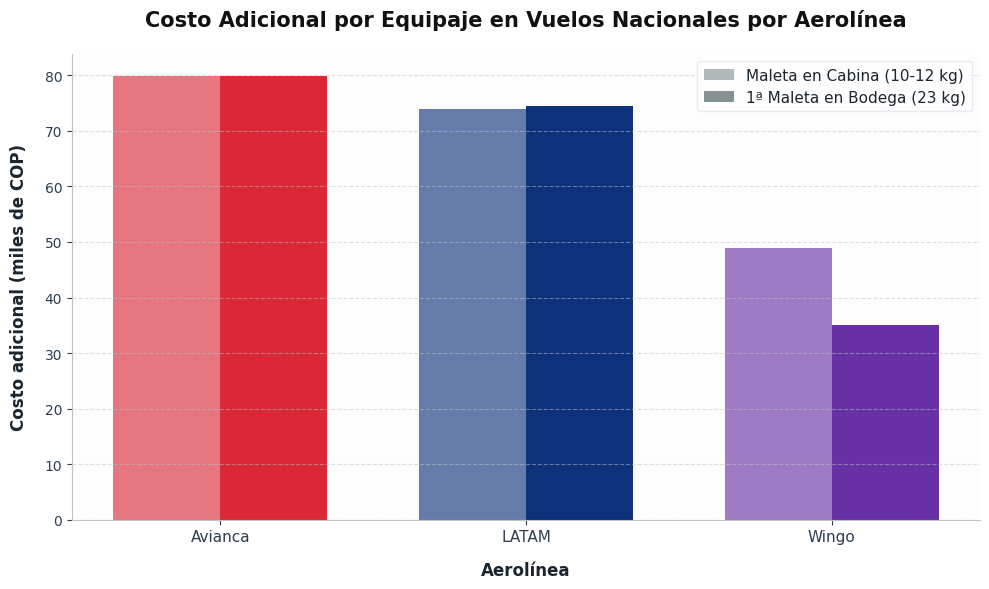

In [ ]:
# ----------------------------------------------------------------------------------------
# GRÁFICO 3: Costo Adicional por Equipaje en Vuelos Nacionales por Aerolínea
# ----------------------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- CONFIGURACIÓN DE ESTILO CORPORATIVO GLOBAL ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['text.color'] = '#1a252f'
plt.rcParams['axes.labelcolor'] = '#1a252f'
plt.rcParams['xtick.color'] = '#2c3e50'
plt.rcParams['ytick.color'] = '#2c3e50'

colores_aerolineas = {
    'Avianca': '#D81C2C',  # Rojo
    'LATAM': '#002673',    # Azul
    'Wingo': '#5F259F'     # Morado
}

x_indices = np.arange(len(equipaje['Aerolinea']))
ancho_barras = 0.35

fig3, ax3 = plt.subplots(figsize=(10, 6), dpi=100)
ax3.set_facecolor('#fdfdfd')

# Mapeamos los colores de borde y de relleno usando transparencias (opacidad)
colors_cabina = [colores_aerolineas[a] for a in equipaje['Aerolinea']]

rects1 = ax3.bar(x_indices - ancho_barras/2, equipaje['Maleta_Cabina_COP'] / 1000, width=ancho_barras, label='Maleta en Cabina (10–12 kg)', color=colors_cabina, alpha=0.6, edgecolor='none')
rects2 = ax3.bar(x_indices + ancho_barras/2, equipaje['Maleta_Bodega_1_COP'] / 1000, width=ancho_barras, label='1ª Maleta en Bodega (23 kg)', color=colors_cabina, alpha=0.95, edgecolor='none')

# Título original exacto, más visible y elegante
ax3.set_title('Costo Adicional por Equipaje en Vuelos Nacionales por Aerolínea', fontsize=15, fontweight='bold', pad=20, color='#111111')
ax3.set_xlabel('Aerolínea', fontsize=12, fontweight='semibold', labelpad=12)
ax3.set_ylabel('Costo adicional (miles de COP)', fontsize=12, fontweight='semibold', labelpad=12)
ax3.set_xticks(x_indices)
ax3.set_xticklabels(equipaje['Aerolinea'], fontsize=11)
ax3.grid(axis='y', linestyle='--', alpha=0.5, color='#bdc3c7')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.spines['left'].set_color('#bdc3c7')
ax3.spines['bottom'].set_color('#bdc3c7')

# Leyenda personalizada indicando la modalidad
legend_elements = [
    Patch(facecolor='#7f8c8d', alpha=0.6, label='Maleta en Cabina (10-12 kg)'),
    Patch(facecolor='#7f8c8d', alpha=0.95, label='1ª Maleta en Bodega (23 kg)')
]
ax3.legend(handles=legend_elements, fontsize=11, frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0')
plt.tight_layout()
plt.show()

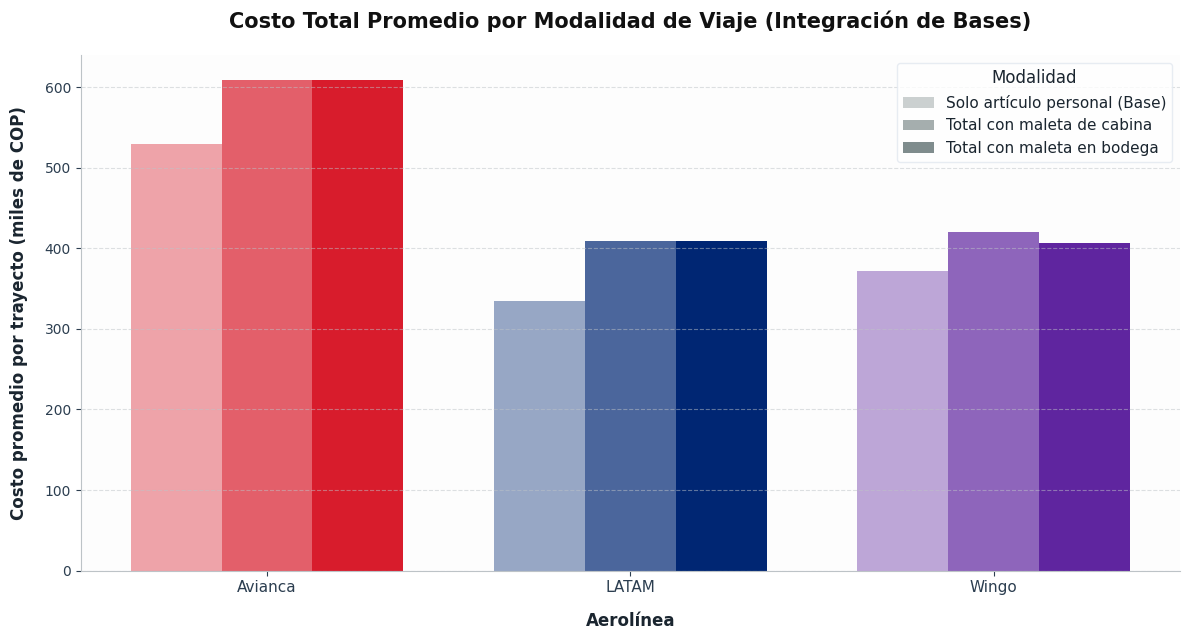

In [ ]:
# ----------------------------------------------------------------------------------------
# GRÁFICO 4: Costo Total Promedio por Modalidad de Viaje (Integración de Bases)
# ----------------------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- CONFIGURACIÓN DE ESTILO CORPORATIVO GLOBAL ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['text.color'] = '#1a252f'
plt.rcParams['axes.labelcolor'] = '#1a252f'
plt.rcParams['xtick.color'] = '#2c3e50'
plt.rcParams['ytick.color'] = '#2c3e50'

colores_aerolineas = {
    'Avianca': '#D81C2C',  # Rojo
    'LATAM': '#002673',    # Azul
    'Wingo': '#5F259F'     # Morado
}

x_final_indices = np.arange(len(tabla_final['Aerolinea']))
ancho_final_barras = 0.25

fig4, ax4 = plt.subplots(figsize=(12, 6.5), dpi=100)
ax4.set_facecolor('#fdfdfd')

for i_idx, row_data in tabla_final.iterrows():
    aerolinea_nombre = row_data['Aerolinea']
    color_base = colores_aerolineas[aerolinea_nombre]

    # Tres barras por aerolínea con gradiente de opacidad para identificar el equipaje extra
    ax4.bar(i_idx - ancho_final_barras, row_data['Tarifa_Base_Prom_COP'] / 1000, width=ancho_final_barras, color=color_base, alpha=0.4, edgecolor='none')
    ax4.bar(i_idx, row_data['Total_Con_Cabina_COP'] / 1000, width=ancho_final_barras, color=color_base, alpha=0.7, edgecolor='none')
    ax4.bar(i_idx + ancho_final_barras, row_data['Total_Con_Bodega_COP'] / 1000, width=ancho_final_barras, color=color_base, alpha=1.0, edgecolor='none')

# Título original exacto, más visible y elegante
ax4.set_title('Costo Total Promedio por Modalidad de Viaje (Integración de Bases)', fontsize=15, fontweight='bold', pad=20, color='#111111')
ax4.set_xlabel('Aerolínea', fontsize=12, fontweight='semibold', labelpad=12)
ax4.set_ylabel('Costo promedio por trayecto (miles de COP)', fontsize=12, fontweight='semibold', labelpad=12)
ax4.set_xticks(x_final_indices)
ax4.set_xticklabels(tabla_final['Aerolinea'], fontsize=11)
ax4.grid(axis='y', linestyle='--', alpha=0.5, color='#bdc3c7')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_color('#bdc3c7')
ax4.spines['bottom'].set_color('#bdc3c7')

legend_modalidades = [
    Patch(facecolor='#7f8c8d', alpha=0.4, label='Solo artículo personal (Base)'),
    Patch(facecolor='#7f8c8d', alpha=0.7, label='Total con maleta de cabina'),
    Patch(facecolor='#7f8c8d', alpha=1.0, label='Total con maleta en bodega')
]
ax4.legend(handles=legend_modalidades, title='Modalidad', fontsize=11, title_fontsize=12, frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0')
plt.tight_layout()
plt.show()